# 9 Wavelet Packet Transform (WPT)

## 9.4 PyWavelets WPT Implementations

### 9.4.2 Basic WPT Example (1D)

In [1]:
import pywt
import numpy as np

# Create sample signal
signal = np.arange(1, 17)  # Equivalent to [1, 2, ..., 16]

# Initialize Wavelet Packet with Daubechies 1 (Haar) wavelet
wp = pywt.WaveletPacket(data=signal, wavelet='db1', mode='periodization')

# Display root node information
print("🔹 Wavelet Packet Tree Root")
print(f"  - Path        : '{wp.path}'")
print(f"  - Level       : {wp.level}")
print(f"  - Max Level   : {wp.maxlevel}")
print(f"  - Original Data: {wp.data.tolist()}")

# Optionally: explore nodes at level 1
print("\n🔹 Level 1 Nodes")
for node in wp.get_level(1, order='natural'):
    print(f"  - Path: {node.path}, Data: {node.data.tolist()}")


🔹 Wavelet Packet Tree Root
  - Path        : ''
  - Level       : 0
  - Max Level   : 4
  - Original Data: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

🔹 Level 1 Nodes
  - Path: a, Data: [2.121320343559643, 4.949747468305834, 7.778174593052023, 10.606601717798213, 13.435028842544405, 16.263455967290597, 19.091883092036785, 21.920310216782973]
  - Path: d, Data: [-0.7071067811865476, -0.7071067811865475, -0.7071067811865479, -0.7071067811865479, -0.707106781186547, -0.7071067811865479, -0.7071067811865461, -0.7071067811865479]


### 9.4.4 Basic WPT Example (2D)

In [1]:
import pywt
import numpy as np

# Create sample 2D image
image = np.random.rand(8, 8)

# Initialize 2D Wavelet Packet
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db1', mode='periodization')

# Display root
print("2D Root Data Shape:", wp2d.data.shape)

# Decompose to level 1
wp2d.decompose()

# Explore level 1 nodes
print("\nLevel 1 Nodes:")
print("A (LL):", wp2d['a'].data.shape)
print("H (LH):", wp2d['h'].data.shape)
print("V (HL):", wp2d['v'].data.shape)
print("D (HH):", wp2d['d'].data.shape)

2D Root Data Shape: (8, 8)

Level 1 Nodes:
A (LL): (4, 4)
H (LH): (4, 4)
V (HL): (4, 4)
D (HH): (4, 4)


### 9.4.6 Basic WPT Example (ND)

In [2]:
# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND Wavelet Packet for 3D
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db1', mode='periodization', axes=(0,1,2))

# Decompose to level 1
wpnd.decompose()

# Explore level 1 nodes (8 subbands)
print("\nLevel 1 Nodes:")
for path in ['aaa', 'aad', 'ada', 'add', 'daa', 'dad', 'dda', 'ddd']:
    print(f"{path}: {wpnd[path].data.shape}")


Level 1 Nodes:
aaa: (4, 4, 4)
aad: (4, 4, 4)
ada: (4, 4, 4)
add: (4, 4, 4)
daa: (4, 4, 4)
dad: (4, 4, 4)
dda: (4, 4, 4)
ddd: (4, 4, 4)


### 9.4.7 Navigating the WPT Tree

**1. Example: 1D Navigation**

In [3]:
import pywt
import numpy as np

# Create sample signal
signal = np.sin(2 * np.pi * 5 * np.linspace(0, 1, 16))

# Initialize WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db2', mode='periodization')

# Decompose to level 2
wp.decompose()
wp.get_level(2, 'freq')

# Access specific nodes
print("Node 'aa' (Approximation at level 2):", wp['aa'].data)
print("Node 'ad' (Detail from approximation):", wp['ad'].data)

# Traverse all nodes at level 2
print("\nAll nodes at level 2:")
for node in wp.get_level(2, 'natural'):
    print(f"Path: {node.path}, Data shape: {node.data.shape}, Data: {node.data.tolist()}")

Node 'aa' (Approximation at level 2): [-0.05412659  0.27063294 -0.27063294  0.05412659]
Node 'ad' (Detail from approximation): [-0.63501588  0.04350953  0.60600953 -0.44751588]

All nodes at level 2:
Path: aa, Data shape: (4,), Data: [-0.054126587736527676, 0.27063293868263755, -0.27063293868263616, 0.05412658773652784]
Path: ad, Data shape: (4,), Data: [-0.6350158773652743, 0.043509526419164, 0.6060095264191657, -0.4475158773652734]
Path: da, Data shape: (4,), Data: [1.0390222283113832, -0.6060095264191638, -0.0435095264191655, 0.47652222831138347]
Path: dd, Data shape: (4,), Data: [-0.10436706131736354, 1.4614178688862411, -1.461417868886239, -0.6456329386826382]


**2. Example: 2D Navigation**

In [4]:
import pywt
import numpy as np

# Create sample 2D image
image = np.random.rand(16, 16)

# Initialize 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db2', mode='periodization')

# Decompose to level 2
wp2d.decompose()
wp2d.get_level(2, 'freq')

# Access specific nodes
print("Node 'ah' (Horizontal detail from approximation):", wp2d['ah'].data.shape)
print("Node 'vv' (Vertical detail at level 2):", wp2d['vv'].data.shape)

# Traverse all nodes at level 2
print("\nAll nodes at level 2:")
for node in wp2d.get_level(2, 'natural'):
    print(f"Path: {node.path}, Data shape: {node.data.shape}")

Node 'ah' (Horizontal detail from approximation): (4, 4)
Node 'vv' (Vertical detail at level 2): (4, 4)

All nodes at level 2:
Path: aa, Data shape: (4, 4)
Path: ah, Data shape: (4, 4)
Path: av, Data shape: (4, 4)
Path: ad, Data shape: (4, 4)
Path: ha, Data shape: (4, 4)
Path: hh, Data shape: (4, 4)
Path: hv, Data shape: (4, 4)
Path: hd, Data shape: (4, 4)
Path: va, Data shape: (4, 4)
Path: vh, Data shape: (4, 4)
Path: vv, Data shape: (4, 4)
Path: vd, Data shape: (4, 4)
Path: da, Data shape: (4, 4)
Path: dh, Data shape: (4, 4)
Path: dv, Data shape: (4, 4)
Path: dd, Data shape: (4, 4)


**3. Example: ND Navigation (3D)**

In [5]:
# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db2', mode='periodization', axes=(0,1,2))

# Decompose to level 1
wpnd.decompose()

# Access specific nodes
print("Node 'aaa' (Low-pass in all axes):", wpnd['aaa'].data.shape)
print("Node 'add' (Detail in third axis):", wpnd['add'].data.shape)

# Traverse all nodes at level 1
print("\nAll nodes at level 1:")
for path in ['aaa', 'aad', 'ada', 'add', 'daa', 'dad', 'dda', 'ddd']:
    print(f"Path: {path}, Data shape: {wpnd[path].data.shape}")

Node 'aaa' (Low-pass in all axes): (4, 4, 4)
Node 'add' (Detail in third axis): (4, 4, 4)

All nodes at level 1:
Path: aaa, Data shape: (4, 4, 4)
Path: aad, Data shape: (4, 4, 4)
Path: ada, Data shape: (4, 4, 4)
Path: add, Data shape: (4, 4, 4)
Path: daa, Data shape: (4, 4, 4)
Path: dad, Data shape: (4, 4, 4)
Path: dda, Data shape: (4, 4, 4)
Path: ddd, Data shape: (4, 4, 4)


### 9.4.8 Node Properties and Attributes

**2. Example: Inspecting Node Properties (1D)**

In [6]:
import pywt
import numpy as np

# Create sample signal
signal = np.arange(1, 17)

# Initialize WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db2', mode='symmetric')

# Decompose to level 2
wp.decompose()
wp.get_level(2, 'natural')

# Inspect properties of node 'ad'
node = wp['ad']
print("Node 'ad' Properties:")
print(f"  - Path: {node.path}")
print(f"  - Level: {node.level}")
print(f"  - Data shape: {node.data.shape}")
print(f"  - Data: {node.data.tolist()}")
print(f"  - Wavelet: {node.wavelet.name}")
print(f"  - Mode: {node.mode}")
print(f"  - Parent path: {node.parent.path if node.parent else 'None'}")

Node 'ad' Properties:
  - Path: ad
  - Level: 2
  - Data shape: (6,)
  - Data: [-0.3325317547305483, -0.2957531754730545, -2.220446049250313e-16, -6.661338147750939e-16, 1.4240381056766593, 0.3080127018922205]
  - Wavelet: db2
  - Mode: symmetric
  - Parent path: a


**3. Example: Inspecting Node Properties (2D)**

In [7]:
image = np.random.rand(16, 16)

# Initialize 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db2', mode='symmetric')

# Decompose to level 1
wp2d.decompose()

# Inspect properties of node 'h' (LH: horizontal details)
node = wp2d['h']
print("Node 'h' Properties:")
print(f"  - Path: {node.path}")
print(f"  - Level: {node.level}")
print(f"  - Data shape: {node.data.shape}")
print(f"  - Wavelet: {node.wavelet.name}")
print(f"  - Mode: {node.mode}")
print(f"  - Parent path: {node.parent.path if node.parent else 'None'}")

Node 'h' Properties:
  - Path: h
  - Level: 1
  - Data shape: (9, 9)
  - Wavelet: db2
  - Mode: symmetric
  - Parent path: 


**4. Example: Inspecting Node Properties (3D)**

In [8]:
# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db2', mode='symmetric', axes=(0,1,2))

# Decompose to level 1
wpnd.decompose()

# Inspect properties of node 'aad'
node = wpnd['aad']
print("Node 'aad' Properties:")
print(f"  - Path: {node.path}")
print(f"  - Level: {node.level}")
print(f"  - Data shape: {node.data.shape}")
print(f"  - Wavelet: {node.wavelet.name}")
print(f"  - Mode: {node.mode}")
print(f"  - Parent path: {node.parent.path if node.parent else 'None'}")

Node 'aad' Properties:
  - Path: aad
  - Level: 1
  - Data shape: (5, 5, 5)
  - Wavelet: db2
  - Mode: symmetric
  - Parent path: 


### 9.4.9 Collecting Nodes by Level

**1. Example: Collecting Nodes by Level (1D)**

In [11]:
import pywt
import numpy as np

# Create sample signal
signal = np.sin(2 * np.pi * 5 * np.linspace(0, 1, 16))

# Initialize WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db2', mode='periodization')

# Decompose to level 3
wp.get_level(2, 'freq')

# Collect nodes at level 2 in 'natural' and 'freq' order
print("Level 2 Nodes (Natural Order):")
for node in wp.get_level(2, 'natural'):
    print(f"  - Path: {node.path}, Data shape: {node.data.shape}")

print("\nLevel 2 Nodes (Frequency Order):")
for node in wp.get_level(2, 'freq'):
    print(f"  - Path: {node.path}, Data shape: {node.data.shape}")

Level 2 Nodes (Natural Order):
  - Path: aa, Data shape: (4,)
  - Path: ad, Data shape: (4,)
  - Path: da, Data shape: (4,)
  - Path: dd, Data shape: (4,)

Level 2 Nodes (Frequency Order):
  - Path: aa, Data shape: (4,)
  - Path: ad, Data shape: (4,)
  - Path: dd, Data shape: (4,)
  - Path: da, Data shape: (4,)


**2. Example: Collecting Nodes by Level (2D)**

In [13]:
import pywt
import numpy as np

# Create sample 2D image
image = np.random.rand(16, 16)

# Initialize 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db2', mode='periodization')

# Decompose to level 2
wp2d.get_level(2, 'freq')

# Define the paths for level 2 in frequency order
# For level 2 in 2D, there are 4^2 = 16 nodes
level_2_paths = [
    'aa', 'ah', 'av', 'ad',
    'ha', 'hh', 'hv', 'hd',
    'va', 'vh', 'vv', 'vd',
    'da', 'dh', 'dv', 'dd'
]

# Collect nodes at level 2
print("Level 2 Nodes (Frequency Order):")
for path in level_2_paths:
    node_data = wp2d[path].data
    if node_data is not None:  # Check if node exists and has data
        print(f"  - Path: {path}, Data shape: {node_data.shape}")
    else:
        print(f"  - Path: {path}, Data: None")

Level 2 Nodes (Frequency Order):
  - Path: aa, Data shape: (4, 4)
  - Path: ah, Data shape: (4, 4)
  - Path: av, Data shape: (4, 4)
  - Path: ad, Data shape: (4, 4)
  - Path: ha, Data shape: (4, 4)
  - Path: hh, Data shape: (4, 4)
  - Path: hv, Data shape: (4, 4)
  - Path: hd, Data shape: (4, 4)
  - Path: va, Data shape: (4, 4)
  - Path: vh, Data shape: (4, 4)
  - Path: vv, Data shape: (4, 4)
  - Path: vd, Data shape: (4, 4)
  - Path: da, Data shape: (4, 4)
  - Path: dh, Data shape: (4, 4)
  - Path: dv, Data shape: (4, 4)
  - Path: dd, Data shape: (4, 4)


**3. Example: Collecting Nodes by Level (3D)**

In [14]:
# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db2', mode='periodization', axes=(0,1,2))

# Decompose to level 1
wpnd.get_level(1)

# Collect nodes at level 1
print("Level 1 Nodes:")
for node in wpnd.get_level(1):
    print(f"  - Path: {node.path}, Data shape: {node.data.shape}")

Level 1 Nodes:
  - Path: aaa, Data shape: (4, 4, 4)
  - Path: aad, Data shape: (4, 4, 4)
  - Path: ada, Data shape: (4, 4, 4)
  - Path: add, Data shape: (4, 4, 4)
  - Path: daa, Data shape: (4, 4, 4)
  - Path: dad, Data shape: (4, 4, 4)
  - Path: dda, Data shape: (4, 4, 4)
  - Path: ddd, Data shape: (4, 4, 4)


### 9.4.10 WPT Reconstruction

**1. Example: 1D Reconstruction**

In [15]:
import pywt
import numpy as np

# Create sample signal
signal = np.sin(2 * np.pi * 5 * np.linspace(0, 1, 16))

# Initialize WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db2', mode='periodization')

# Decompose to level 2
wp.get_level(2, 'freq')

# Full reconstruction (update=False)
reconstructed = wp.reconstruct(update=False)
print("Reconstruction MSE (update=False):", np.mean((signal - reconstructed)**2))

# Modify a node and reconstruct with update=True
wp['ad'].data *= 0  # Zero out 'ad' coefficients
wp.reconstruct(update=True)
print("Modified node data (after update=True):", wp[''].data[:5])  # Root node updated

Reconstruction MSE (update=False): 2.4290685232494516e-32
Modified node data (after update=True): [-0.33767525  1.04494668 -0.37056771 -0.0230819   0.54816186]


**2. Example: 2D Reconstruction**

In [16]:
# Create sample 2D image
image = np.random.rand(16, 16)

# Initialize 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db2', mode='periodization')

# Decompose to level 2
wp2d.get_level(2, 'freq')

# Full reconstruction (update=False)
reconstructed = wp2d.reconstruct(update=False)
print("2D Reconstruction MSE (update=False):", np.mean((image - reconstructed)**2))

# Selective reconstruction: only 'aa' node
wp_copy = pywt.WaveletPacket2D(data=None, wavelet='db2', mode='periodization')
wp_copy['aa'] = wp2d['aa']
approx_recon = wp_copy.reconstruct(update=False)
print("2D Approximation-only Reconstruction MSE:", np.mean((image - approx_recon)**2))

2D Reconstruction MSE (update=False): 4.8321892635184365e-32
2D Approximation-only Reconstruction MSE: 0.07798550388364603


**3. Example: ND Reconstruction**

In [17]:
# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db2', mode='periodization', axes=(0,1,2))

# Decompose to level 1
wpnd.get_level(1)

# Full reconstruction (update=False)
reconstructed = wpnd.reconstruct(update=False)
print("3D Reconstruction MSE (update=False):", np.mean((volume - reconstructed)**2))

# Selective reconstruction: only 'aaa' node
wp_copy = pywt.WaveletPacketND(data=None, wavelet='db2', mode='periodization', axes=(0,1,2))
wp_copy['aaa'] = wpnd['aaa']
approx_recon = wp_copy.reconstruct(update=False)
print("3D Approximation-only Reconstruction MSE:", np.mean((volume - approx_recon)**2))

3D Reconstruction MSE (update=False): 3.777516924051067e-32
3D Approximation-only Reconstruction MSE: 0.0778258767039172


### 9.4.11 Advanced Node Operations

**1. Example: Advanced Node Operations (1D)**

In [23]:
import pywt
import numpy as np

# Create sample signal with more samples
signal = np.sin(2 * np.pi * 5 * np.linspace(0, 1, 64))  # Increased to 64 samples

# Initialize WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db2', mode='periodization')

# Check maximum decomposition level
print(f"Maximum decomposition level: {wp.maxlevel}")  # Should be 3 or higher

# Decompose to level 3
wp.get_level(3, 'freq')

# Collect leaf nodes
leaf_nodes = wp.get_leaf_nodes()  # Remove 'recursive=True'
print("Leaf Nodes:")
for node in leaf_nodes:
    print(f"  - Path: {node.path}, Level: {node.level}")

# Remove node 'aad' and reconstruct
wp['aad'].data = None  # Remove node
recon_no_aad = wp.reconstruct(update=False)
print("Reconstruction MSE without 'aad':", np.mean((signal - recon_no_aad)**2))

# Restore node 'aad' by recomputing
wp['aa'].decompose()  # Recompute children of 'aa'
recon_restored = wp.reconstruct(update=False)
print("Reconstruction MSE after restoring 'aad':", np.mean((signal - recon_restored)**2))

Maximum decomposition level: 4
Leaf Nodes:
  - Path: aaa, Level: 3
  - Path: aad, Level: 3
  - Path: ada, Level: 3
  - Path: add, Level: 3
  - Path: daa, Level: 3
  - Path: dad, Level: 3
  - Path: dda, Level: 3
  - Path: ddd, Level: 3
Reconstruction MSE without 'aad': 0.3378151707121775
Reconstruction MSE after restoring 'aad': 3.525135169354595e-32


**2. Example: Advanced Node Operations (2D)**

In [25]:
import pywt
import numpy as np

# Create sample 2D image
image = np.random.rand(16, 16)

# Initialize 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db2', mode='periodization')

# Check maximum decomposition level
print(f"Maximum decomposition level: {wp2d.maxlevel}")

# Decompose to level 2
wp2d.get_level(2, 'freq')

# Collect leaf nodes
leaf_nodes = wp2d.get_leaf_nodes()  # Remove 'recursive=True'
print("Leaf Nodes:")
for node in leaf_nodes:
    print(f"  - Path: {node.path}, Level: {node.level}")

# Remove high-frequency node 'dd' and reconstruct
wp2d['dd'].data = None
recon_no_dd = wp2d.reconstruct(update=False)
print("2D Reconstruction MSE without 'dd':", np.mean((image - recon_no_dd)**2))

# Restore 'dd' by recomputing
wp2d['d'].decompose()
recon_restored = wp2d.reconstruct(update=False)
print("2D Reconstruction MSE after restoring 'dd':", np.mean((image - recon_restored)**2))
# Restore 'dd' by recomputing
wp2d['d'].decompose()
recon_restored = wp2d.reconstruct(update=False)
print("2D Reconstruction MSE after restoring 'dd':", np.mean((image - recon_restored)**2))

Maximum decomposition level: 2
Leaf Nodes:
  - Path: aa, Level: 2
  - Path: ah, Level: 2
  - Path: av, Level: 2
  - Path: ad, Level: 2
  - Path: ha, Level: 2
  - Path: hh, Level: 2
  - Path: hv, Level: 2
  - Path: hd, Level: 2
  - Path: va, Level: 2
  - Path: vh, Level: 2
  - Path: vv, Level: 2
  - Path: vd, Level: 2
  - Path: da, Level: 2
  - Path: dh, Level: 2
  - Path: dv, Level: 2
  - Path: dd, Level: 2
2D Reconstruction MSE without 'dd': 0.006907450975779405
2D Reconstruction MSE after restoring 'dd': 5.287655708642847e-32
2D Reconstruction MSE after restoring 'dd': 5.287655708642847e-32


**3. Example: Advanced Node Operations (3D)**

In [27]:
import pywt
import numpy as np

# Create sample 3D volume
volume = np.random.rand(8, 8, 8)

# Initialize ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db2', mode='periodization', axes=(0,1,2))

# Check maximum decomposition level
print(f"Maximum decomposition level: {wpnd.maxlevel}")

# Decompose to level 1
wpnd.get_level(1)

# Collect leaf nodes
leaf_nodes = wpnd.get_leaf_nodes()  # Remove 'recursive=True'
print("Leaf Nodes:")
for node in leaf_nodes:
    print(f"  - Path: {node.path}, Level: {node.level}")

# Remove node 'ddd' and reconstruct
wpnd['ddd'].data = None
recon_no_ddd = wpnd.reconstruct(update=False)
print("3D Reconstruction MSE without 'ddd':", np.mean((volume - recon_no_ddd)**2))

# Restore 'ddd' by recomputing
wpnd.decompose()  # Recompute level 1
recon_restored = wpnd.reconstruct(update=False)
print("3D Reconstruction MSE after restoring 'ddd':", np.mean((volume - recon_restored)**2))

Maximum decomposition level: 1
Leaf Nodes:
  - Path: aaa, Level: 1
  - Path: aad, Level: 1
  - Path: ada, Level: 1
  - Path: add, Level: 1
  - Path: daa, Level: 1
  - Path: dad, Level: 1
  - Path: dda, Level: 1
  - Path: ddd, Level: 1
3D Reconstruction MSE without 'ddd': 0.006642509678676058
3D Reconstruction MSE after restoring 'ddd': 4.1384642194145586e-32


## 9.5 Complete Implementation Example

### 9.5.1 1D Example

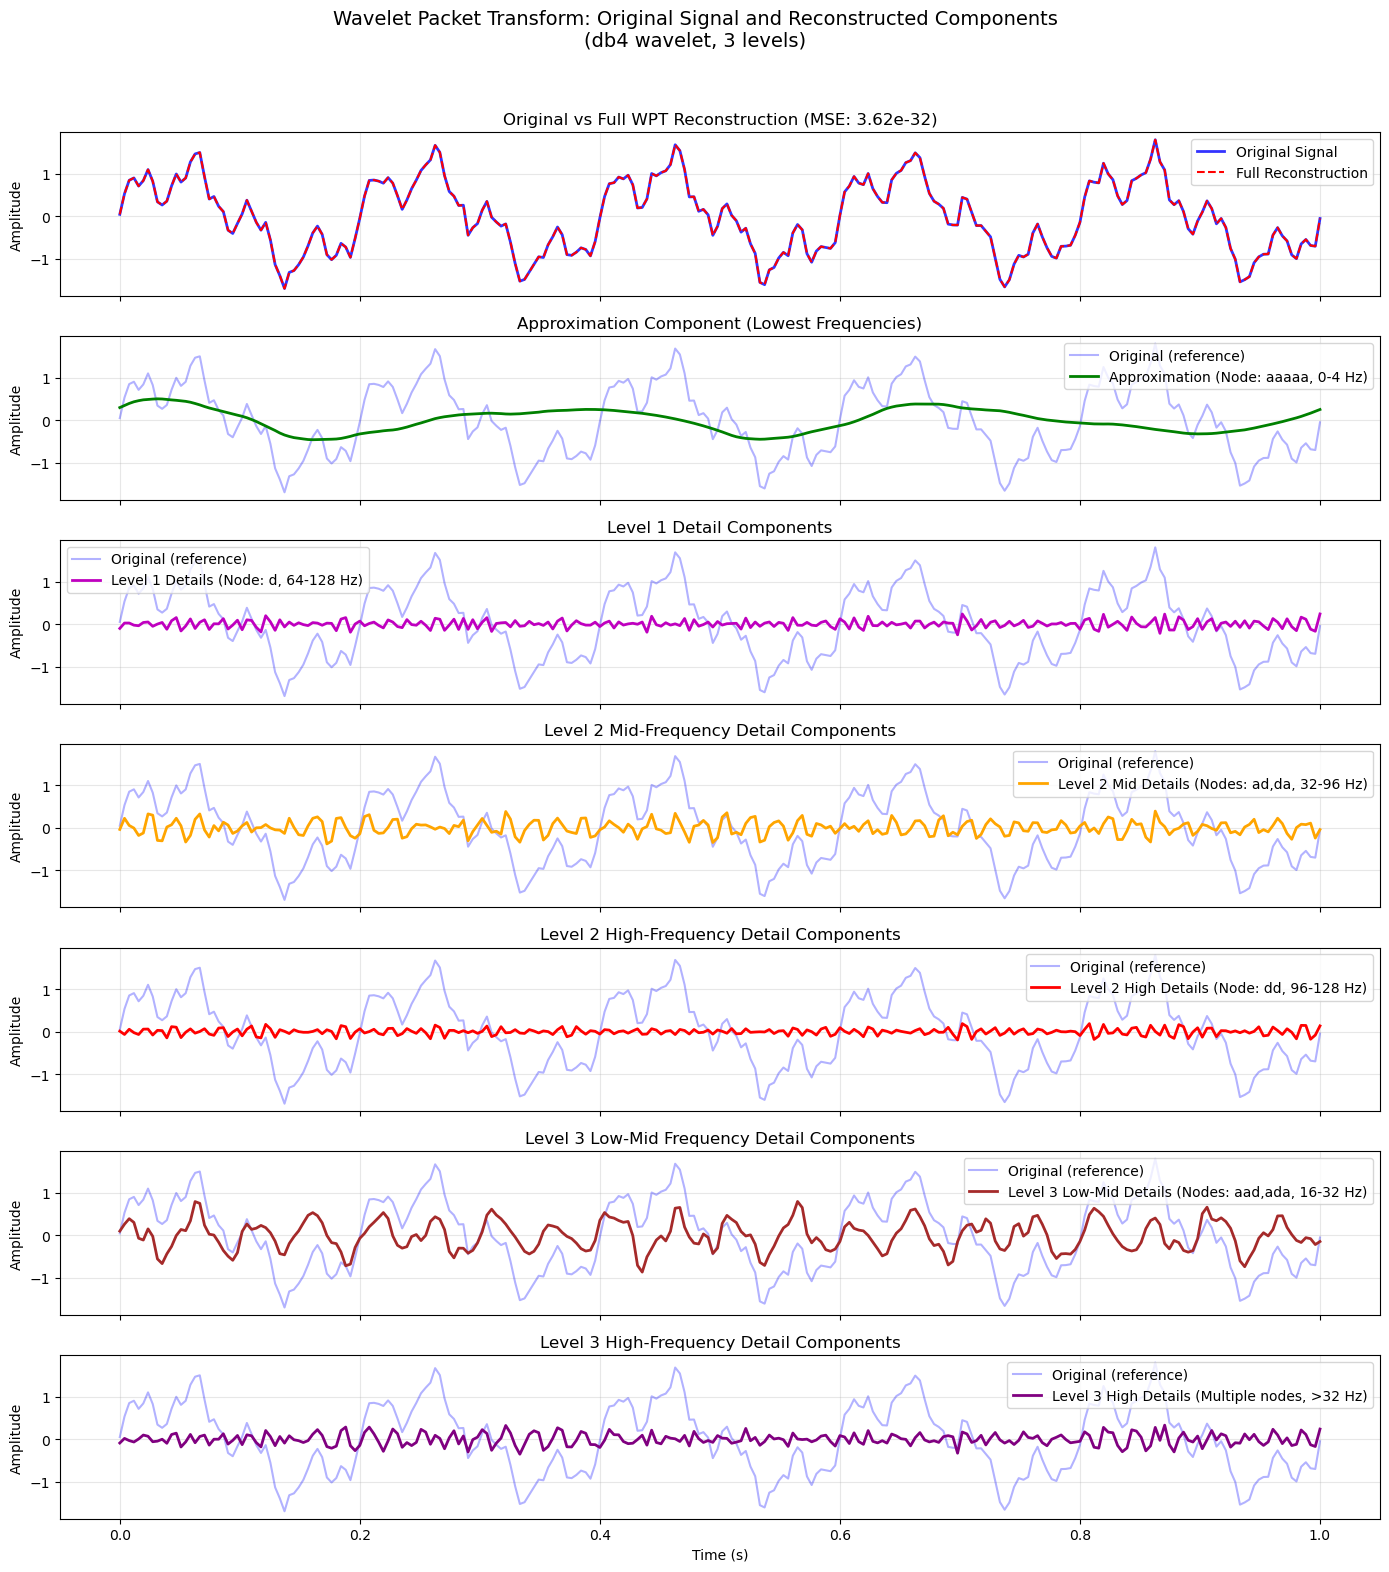

WPT Analysis Results:
WPT Analysis Results for Level 1:
Number of coefficient sets: 2
Coefficient paths: ['a', 'd']
WPT Analysis Results for Level 2:
Number of coefficient sets: 4
Coefficient paths: ['aa', 'ad', 'dd', 'da']
WPT Analysis Results for Level 3:
Number of coefficient sets: 8
Coefficient paths: ['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']
Reconstruction error (MSE): 1.21e-31


In [28]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Create synthetic noisy signal
t = np.linspace(0, 1, 256)
fs = len(t)

# Multi-component signal
signal = (np.sin(2 * np.pi * 5 * t) +           # Low frequency: 5 Hz
          0.5 * np.sin(2 * np.pi * 20 * t) +    # Medium frequency: 20 Hz
          0.2 * np.sin(2 * np.pi * 50 * t))     # High frequency: 50 Hz

np.random.seed(42)
signal += 0.1 * np.random.randn(len(signal))

# Analyze with WPT
wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='periodization')
coeffs_by_level = {}

for level in range(1, 4):  # Decompose up to 3 levels
    nodes = wp.get_level(level, 'freq')
    coeffs = [node.data for node in nodes]
    paths = [node.path for node in nodes]
    coeffs_by_level[level] = {
        'paths': paths,
        'coeffs': coeffs,
        'nodes': nodes
    }

# Full reconstruction
reconstructed_full = wp.reconstruct()

# Partial reconstruction: approximation and details
max_level = wp.maxlevel
approx_reconstruction = np.zeros_like(signal)
if max_level >= 3:
    node_path = 'a' * max_level
    wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
    for node in wp_copy.get_level(max_level, 'freq'):
        if node.path == node_path:
            wp_copy[node.path].data = wp[node.path].data
        else:
            wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
    approx_reconstruction = wp_copy.reconstruct()

detail_level1 = np.zeros_like(signal)
node_path = 'd'
wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
for node in wp_copy.get_level(1, 'freq'):
    if node.path == node_path:
        wp_copy[node.path].data = wp[node.path].data
    else:
        wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
detail_level1 = wp_copy.reconstruct()

detail_level2_mid = np.zeros_like(signal)
if max_level >= 2:
    node_paths = ['ad', 'da']
    wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
    for node in wp_copy.get_level(2, 'freq'):
        if node.path in node_paths:
            wp_copy[node.path].data = wp[node.path].data
        else:
            wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
    detail_level2_mid = wp_copy.reconstruct()

detail_level2_high = np.zeros_like(signal)
if max_level >= 2:
    node_path = 'dd'
    wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
    for node in wp_copy.get_level(2, 'freq'):
        if node.path == node_path:
            wp_copy[node.path].data = wp[node.path].data
        else:
            wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
    detail_level2_high = wp_copy.reconstruct()

detail_level3_low = np.zeros_like(signal)
if max_level >= 3:
    node_paths = ['aad', 'ada']
    wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
    for node in wp_copy.get_level(3, 'freq'):
        if node.path in node_paths:
            wp_copy[node.path].data = wp[node.path].data
        else:
            wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
    detail_level3_low = wp_copy.reconstruct()

detail_level3_high = np.zeros_like(signal)
if max_level >= 3:
    all_level3_nodes = [node.path for node in wp.get_level(3, 'freq')]
    high_freq_nodes = [path for path in all_level3_nodes if path not in ['aaa', 'aad', 'ada']]
    wp_copy = pywt.WaveletPacket(data=signal.copy(), wavelet='db4', mode='periodization')
    for node in wp_copy.get_level(3, 'freq'):
        if node.path in high_freq_nodes:
            wp_copy[node.path].data = wp[node.path].data
        else:
            wp_copy[node.path].data = np.zeros_like(wp[node.path].data)
    detail_level3_high = wp_copy.reconstruct()

# Create comprehensive plot
fig, axes = plt.subplots(7, 1, figsize=(14, 16), sharex=True)
mse_full = np.mean((signal - reconstructed_full)**2)

# Plot 1: Original vs Full Reconstruction
axes[0].plot(t, signal, 'b-', label='Original Signal', linewidth=2, alpha=0.8)
axes[0].plot(t, reconstructed_full, 'r--', label='Full Reconstruction', linewidth=1.5)
axes[0].set_title(f'Original vs Full WPT Reconstruction (MSE: {mse_full:.2e})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Approximation (lowest frequencies)
axes[1].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
approx_label = f'Approximation (Node: {"a" * max_level}, 0-{fs/(2**(max_level+1)):.0f} Hz)'
axes[1].plot(t, approx_reconstruction, 'g-', label=approx_label, linewidth=2)
axes[1].set_title('Approximation Component (Lowest Frequencies)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Level 1 Details (high frequencies)
axes[2].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
axes[2].plot(t, detail_level1, 'm-', label=f'Level 1 Details (Node: d, {fs//4:.0f}-{fs//2:.0f} Hz)', linewidth=2)
axes[2].set_title('Level 1 Detail Components')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Plot 4: Level 2 Mid-frequency Details
axes[3].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
if max_level >= 2:
    axes[3].plot(t, detail_level2_mid, 'orange', label=f'Level 2 Mid Details (Nodes: ad,da, {fs//8:.0f}-{3*fs//8:.0f} Hz)', linewidth=2)
else:
    axes[3].plot(t, detail_level2_mid, 'orange', label='Level 2 Mid Details (N/A)', linewidth=2)
axes[3].set_title('Level 2 Mid-Frequency Detail Components')
axes[3].legend()
axes[3].grid(True, alpha=0.3)

# Plot 5: Level 2 High-frequency Details
axes[4].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
if max_level >= 2:
    axes[4].plot(t, detail_level2_high, 'red', label=f'Level 2 High Details (Node: dd, {3*fs//8:.0f}-{fs//2:.0f} Hz)', linewidth=2)
else:
    axes[4].plot(t, detail_level2_high, 'red', label='Level 2 High Details (N/A)', linewidth=2)
axes[4].set_title('Level 2 High-Frequency Detail Components')
axes[4].legend()
axes[4].grid(True, alpha=0.3)

# Plot 6: Level 3 Low-Mid Details
axes[5].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
if max_level >= 3:
    axes[5].plot(t, detail_level3_low, 'brown', label=f'Level 3 Low-Mid Details (Nodes: aad,ada, {fs//16:.0f}-{fs//8:.0f} Hz)', linewidth=2)
else:
    axes[5].plot(t, detail_level3_low, 'brown', label='Level 3 Low-Mid Details (N/A)', linewidth=2)
axes[5].set_title('Level 3 Low-Mid Frequency Detail Components')
axes[5].legend()
axes[5].grid(True, alpha=0.3)

# Plot 7: Level 3 Various High Details
axes[6].plot(t, signal, 'b-', alpha=0.3, label='Original (reference)')
if max_level >= 3:
    axes[6].plot(t, detail_level3_high, 'purple', label=f'Level 3 High Details (Multiple nodes, >{fs//8:.0f} Hz)', linewidth=2)
else:
    axes[6].plot(t, detail_level3_high, 'purple', label='Level 3 High Details (N/A)', linewidth=2)
axes[6].set_title('Level 3 High-Frequency Detail Components')
axes[6].legend()
axes[6].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
for ax in axes:
    ax.set_ylabel('Amplitude')

plt.suptitle('Wavelet Packet Transform: Original Signal and Reconstructed Components\n(db4 wavelet, 3 levels)', 
             fontsize=14, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

# Print WPT Analysis Results and Reconstruction Verification
print("WPT Analysis Results:")
for level in range(1, 4):
    coeffs = coeffs_by_level[level]['coeffs']
    paths = coeffs_by_level[level]['paths']
    print(f"WPT Analysis Results for Level {level}:")
    print(f"Number of coefficient sets: {len(coeffs)}")
    print(f"Coefficient paths: {paths}")

reconstructed = wp.reconstruct()
reconstruction_error = np.mean((signal - reconstructed)**2)
print(f"Reconstruction error (MSE): {reconstruction_error:.2e}")

### 9.5.2 2D Example: Image Decomposition and Reconstruction

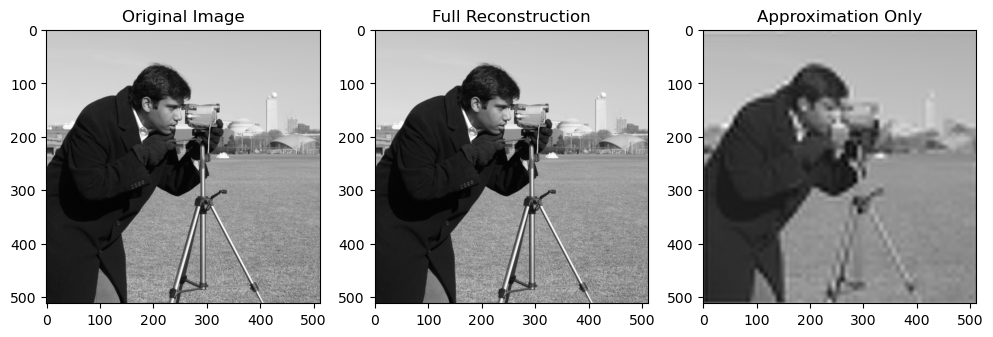

In [29]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import camera  # Sample image

# Load sample image
image = camera().astype(np.float64) / 255.0  # Normalize

# Perform 2D WPT
wp2d = pywt.WaveletPacket2D(data=image, wavelet='db4', mode='periodization', maxlevel=3)

# Decompose fully
for level in range(1, 4):
    wp2d.get_level(level, 'freq')  # Forces decomposition

# Reconstruct full image
reconstructed = wp2d.reconstruct()

# Partial reconstruction: Keep only approximation at level 3
wp_copy = pywt.WaveletPacket2D(data=None, wavelet='db4', mode='periodization')
wp_copy['aaa'] = wp2d['aaa']  # Lowest frequency
approx_recon = wp_copy.reconstruct()

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[1].imshow(reconstructed, cmap='gray')
axes[1].set_title('Full Reconstruction')
axes[2].imshow(approx_recon, cmap='gray')
axes[2].set_title('Approximation Only')
plt.show()

### 9.5.3 ND Example: 3D Volume Decomposition and Reconstruction

Maximum decomposition level: 3
Full Reconstruction MSE: 3.07e-31
Approximation-only ('aaa') Reconstruction MSE: 1.76e-01


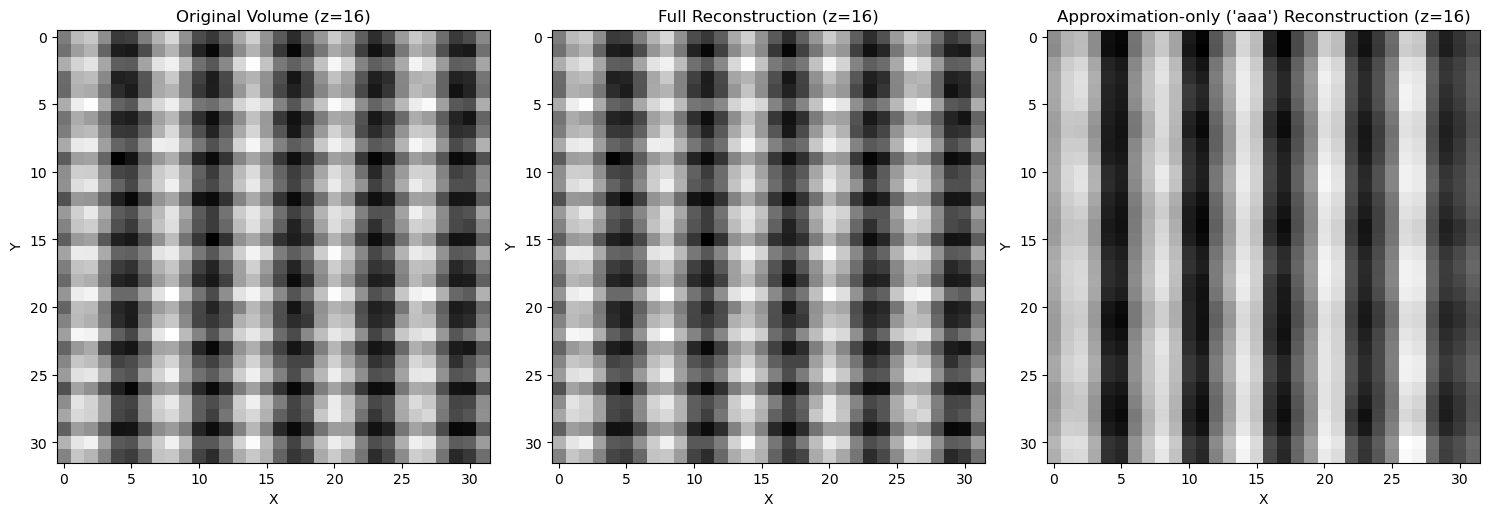

In [31]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Create synthetic 3D volume
t = np.linspace(0, 1, 32)
x, y, z = np.meshgrid(t, t, t)
volume = np.sin(2 * np.pi * 5 * x) + 0.5 * np.sin(2 * np.pi * 20 * y) + 0.2 * np.sin(2 * np.pi * 50 * z)
volume += 0.1 * np.random.randn(32, 32, 32)

# Perform ND WPT
wpnd = pywt.WaveletPacketND(data=volume, wavelet='db4', mode='periodization', maxlevel=3, axes=(0,1,2))

# Check maximum decomposition level
print(f"Maximum decomposition level: {wpnd.maxlevel}")

# Decompose fully
for level in range(1, 4):
    wpnd.get_level(level)  # Forces decomposition

# Reconstruct full volume
reconstructed = wpnd.reconstruct()

# Partial reconstruction: Low-frequency 'aaa'
wp_copy = pywt.WaveletPacketND(data=None, wavelet='db4', mode='periodization', axes=(0,1,2))
wp_copy['aaa'] = wpnd['aaa']
approx_recon = wp_copy.reconstruct()

# Verification
mse_full = np.mean((volume - reconstructed)**2)
mse_approx = np.mean((volume - approx_recon)**2)
print(f"Full Reconstruction MSE: {mse_full:.2e}")
print(f"Approximation-only ('aaa') Reconstruction MSE: {mse_approx:.2e}")

# Plotting 2D slices (z=16, middle of the 32x32x32 volume)
slice_idx = 16
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(volume[:, :, slice_idx], cmap='gray')
axes[0].set_title('Original Volume (z=16)')
axes[1].imshow(reconstructed[:, :, slice_idx], cmap='gray')
axes[1].set_title('Full Reconstruction (z=16)')
axes[2].imshow(approx_recon[:, :, slice_idx], cmap='gray')
axes[2].set_title("Approximation-only ('aaa') Reconstruction (z=16)")
for ax in axes:
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axis('on')  # Keep axes for clarity
plt.tight_layout()
plt.show()

**Additional Visualization Options**

If you want to visualize multiple slices or a different axis, you can modify the slice selection. For example, to plot slices along the x-axis:

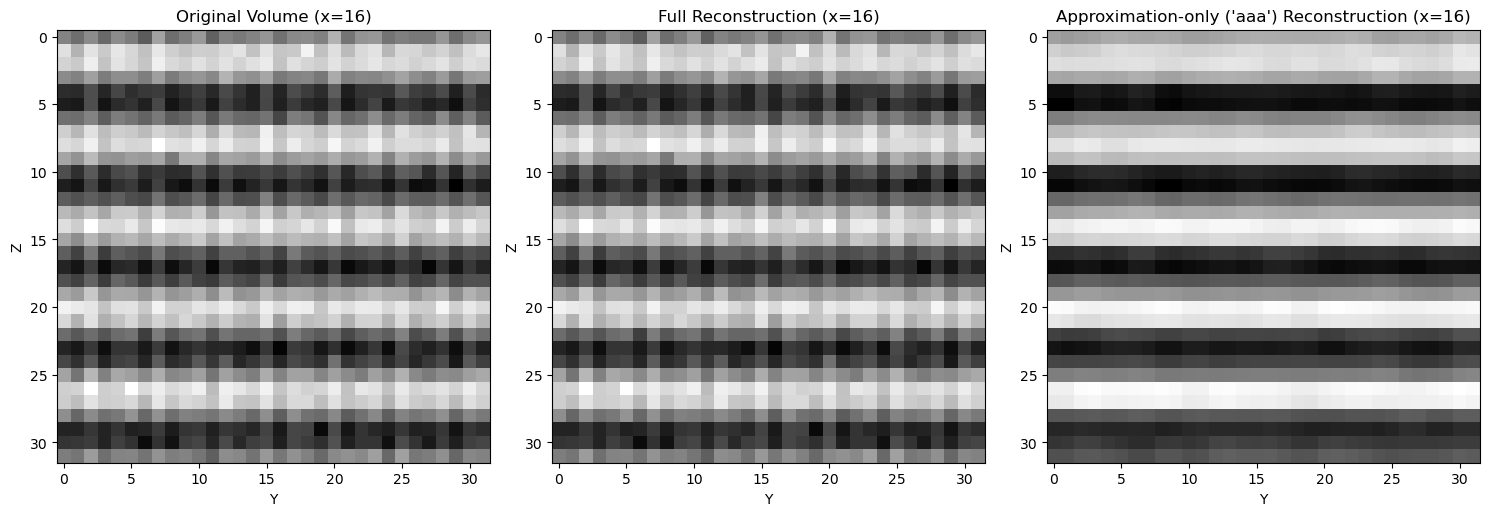

In [32]:
# Plot slices along x-axis (x=16)
slice_idx = 16
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(volume[slice_idx, :, :], cmap='gray')
axes[0].set_title('Original Volume (x=16)')
axes[1].imshow(reconstructed[slice_idx, :, :], cmap='gray')
axes[1].set_title('Full Reconstruction (x=16)')
axes[2].imshow(approx_recon[slice_idx, :, :], cmap='gray')
axes[2].set_title("Approximation-only ('aaa') Reconstruction (x=16)")
for ax in axes:
    ax.set_xlabel('Y')
    ax.set_ylabel('Z')
    ax.axis('on')
plt.tight_layout()
plt.show()

Or, to plot multiple slices (e.g., z=8, 16, 24):

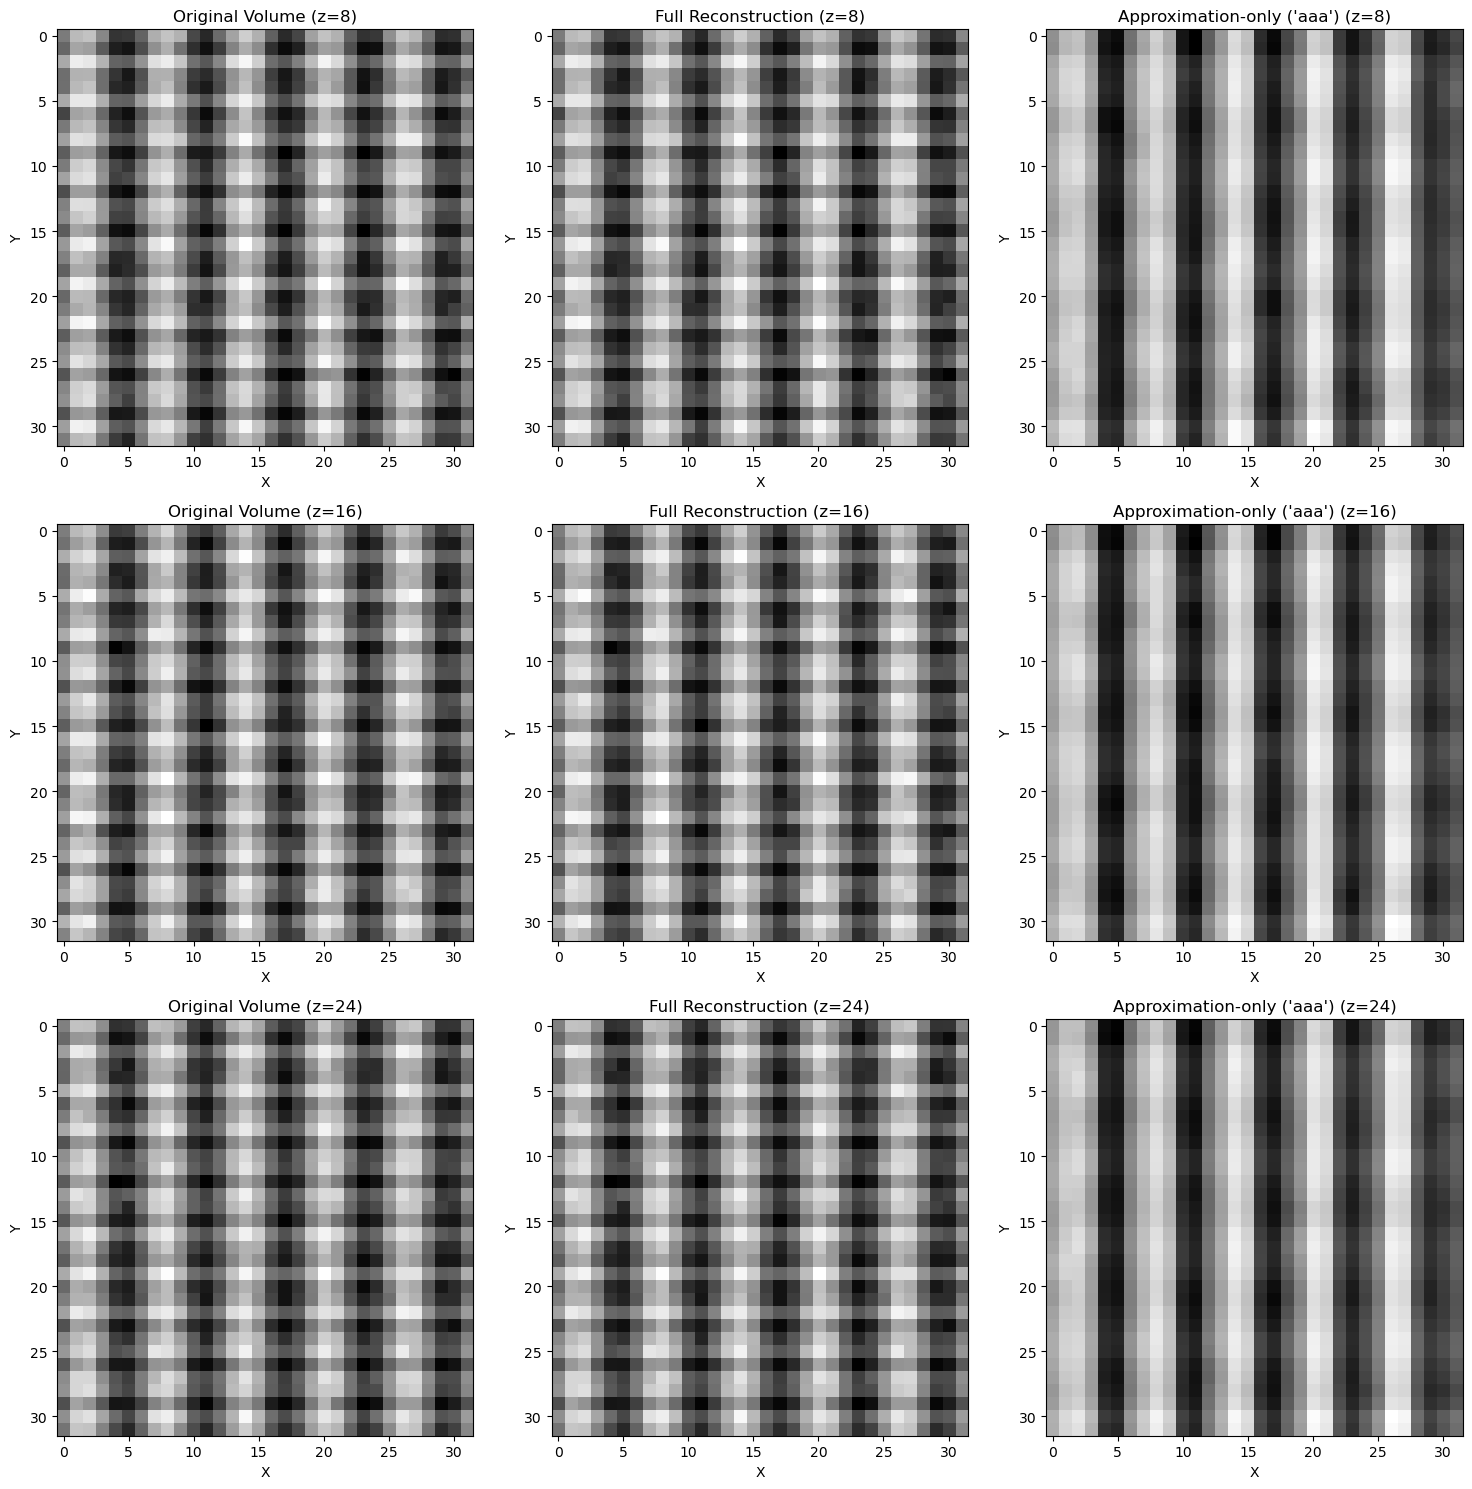

In [33]:
# Plot multiple z-slices
slice_indices = [8, 16, 24]
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, slice_idx in enumerate(slice_indices):
    axes[i, 0].imshow(volume[:, :, slice_idx], cmap='gray')
    axes[i, 0].set_title(f'Original Volume (z={slice_idx})')
    axes[i, 1].imshow(reconstructed[:, :, slice_idx], cmap='gray')
    axes[i, 1].set_title(f'Full Reconstruction (z={slice_idx})')
    axes[i, 2].imshow(approx_recon[:, :, slice_idx], cmap='gray')
    axes[i, 2].set_title(f"Approximation-only ('aaa') (z={slice_idx})")
    for ax in axes[i]:
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.axis('on')
plt.tight_layout()
plt.show()